In [1]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
#from ccsblib import  huri
from Load_CCSB_Data import GetOrfMapping
from load_edgotyping_data import load_qY2H
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable

%matplotlib inline
%config InlineBackend.figure_format='retina'

pd.options.display.max_rows = 1000
pd.options.display.max_columns = 60

In [2]:
from glob import glob

In [3]:
allele_info_df = pd.read_csv('../../../database_management/20220228_Mikko_table_creation_and_updates/VUS_wt_allele_collection_entry_plates_allele_infos.csv', index_col=0)
#allele_info_df.query('orf_id == 7215.0 and mutation_id == 1976.0')
allele_info_d = {(orf_id,mutation_id):(nt_change,aa_change,'to_be_verified') for orf_id,mutation_id,nt_change,aa_change 
                 in zip(allele_info_df.orf_id, allele_info_df.mutation_id, allele_info_df.ensg, allele_info_df.nt_change)
                 if mutation_id == mutation_id
                }

allele_info_df.head()

,orf_id,symbol,node_type,mutation_id,entry_plate,entry_well,entry_well_id,ensg,nt_change,aa_change,chr,chr_pos_37,chr_pos_38
0,300,GALT,disease_wt,NaN,DisWTGDEh01,A01,1,NaN,NaN,NaN,NaN,NaN,NaN
1,12132,HCFC1,disease_wt,NaN,DisWTGDEh01,B01,2,NaN,NaN,NaN,NaN,NaN,NaN
2,7515,XRCC4,disease_wt,NaN,DisWTGDEh01,C01,3,NaN,NaN,NaN,NaN,NaN,NaN
3,10165,CRYBB1,disease_wt,NaN,DisWTGDEh01,D01,4,NaN,NaN,NaN,NaN,NaN,NaN
4,71642,CACNB4,disease_wt,NaN,DisWTGDEh01,E01,5,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
allele_collection = GetDFv2()

for i, (orf_id,nt_change,aa_change,symbol,ensg,entrez,rc4_mut_id,cegs_mut_id,vus_mut_id,rc4_plate,rc4_well,cegs_plate,cegs_well,vus_plate,vus_well,chr,chr_pos_37,chr_pos_38,cv_allele_id,hgmd_id,cv_clinical_significance,cv_phenotypes,cv_phenotype_ids,hgmd_clinical_significance,hgmd_phenotype,clinical_significance) in allele_collection.iterrows():
    for mut_id in [rc4_mut_id,cegs_mut_id,vus_mut_id]:
        if mut_id == mut_id:
            allele_info_d[orf_id,mut_id] = (nt_change,aa_change,clinical_significance)

#allele_collection.head()

In [5]:
orf_mapping = GetOrfMapping()
orf_to_symbol = dict(zip(orf_mapping.orf_id, orf_mapping.symbol))
ensg_to_symbol = dict(zip(orf_mapping.ensembl_gene_id, orf_mapping.symbol))

## Load raw data

In [6]:
res = {}
for file in glob('20230215_Full_scale_readout/*.xls'):

    df = pd.read_excel(file, skiprows=10, skipfooter=35, engine='xlrd')
    df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)
    
    if 'PRS' in file:
        pla = file.split('_')[-1][:-4]
        r = (int(file.split('_')[-3].split('/')[-1]) // 87)+1
        
        
        pla = f'{pla}_r{r}'
        
    else:
        if 'splashed' in file:
            pla = int(file.split('_')[-2])
            #print(file, pla)
        else:
            pla = int(file.split('_')[-1][:-4])
        
    #print(file, pla)
        
    value_d = dict()
    for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
        for i, value in enumerate(row):
            key = (pla,f'{l}{str(i+1).zfill(2)}')
            res[key] = value

*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: will use 'iso-8859-1'
*** No CODEPAGE record, no encoding_override: wi

In [7]:
empty_well_df = pd.read_excel('20230214_nY2H_post_diploid_selection.xlsx', header=None, skiprows=2)
empty_well_df.rename(columns={0:'plate_name', 1:'wells'}, inplace=True)
empty_well_df['plate_name'] = empty_well_df.plate_name.apply(lambda x: x.replace('AD2BxDB1A','AD2BxDB2A'))
empty_well_df['pla_id'] = empty_well_df.plate_name.apply(lambda x: int(x.split('_')[-1]) if 'NY2H' in x else np.nan)
empty_well_df['wells_set'] =  empty_well_df.wells.apply(lambda x: set(x.replace(' ','').split(',')))

empty_well_retest_d = {pla_id:wells_set for pla_id, wells_set in zip(empty_well_df.pla_id, empty_well_df.wells_set)}
#empty_well_df['plate_name'] = empty_well_df.apply(lambda x: x.replace('AD1AxDB1B','DB1A_ADB'))

empty_well_prsrrs_d = {f'{plate_name.split("_")[-1]}r{(int(plate_name.split(".")[0])//87)+1}':wells_set for plate_name, wells_set in zip(empty_well_df.plate_name, empty_well_df.wells_set) if 'PRS' in plate_name}

empty_well_df['prs_repeat'] = [f'r{(int(plate_name.split(".")[0])//87)+1}'  if 'PRS' in plate_name else np.nan for plate_name in empty_well_df.plate_name]
empty_well_df['prs_orient'] = empty_well_df.plate_name.apply(lambda x: x if 'PRS' not in x else 'DBA_ADB' if x[-1] == 'A' else 'DBB_ADA')
empty_well_df['empty_ctrl'] = empty_well_df.plate_name.apply(lambda x: 'empty' in x)
empty_well_df['prs_orient'] = [orient if not ectrl else  f'{orient[:3]}_EAD' for orient, ectrl in zip(empty_well_df.prs_orient,empty_well_df.empty_ctrl)]

empty_well_df['prs_pla_id'] = empty_well_df.plate_name.apply(lambda x: int(x[-2]) if 'PRS' in x else np.nan)

empty_well_df['prs_pla'] = empty_well_df.plate_name.apply(lambda x: 'PRS' in x)

empty_well_prsrrs_d = {(prs_repeat,prs_pla_id,prs_orient):wells_set for prs_repeat,prs_pla_id, prs_orient, wells_set in zip(empty_well_df.prs_repeat,empty_well_df.prs_pla_id,empty_well_df.prs_orient,empty_well_df.wells_set)}

empty_well_df.head()

,plate_name,wells,pla_id,wells_set,prs_repeat,prs_orient,empty_ctrl,prs_pla_id,prs_pla
0,1. hPRSRRSv2_AD1AxDB1B,"B01, C01, E01, H01, B02, A03, B04, G04, H04, C...",NaN,"{H06, G12, A12, F12, D06, H08, F11, H01, C05, ...",r1,DBB_ADA,False,1.0,True
1,2. hPRSRRSv2_AD1BxDB1A,"B01, C01, E01, B02, A03, B04, G04, H04, C05, D...",NaN,"{H06, G12, A12, F12, D06, H08, F11, C05, C01, ...",r1,DBA_ADB,False,1.0,True
2,3. hPRSRRSv2_AD2AxDB2B,"A01, B01, C01, G01, D02, G02, A03, H03, E04, H...",NaN,"{F07, H06, B10, G12, F12, G06, E05, C01, G02, ...",r1,DBB_ADA,False,2.0,True
3,4. hPRSRRSv2_AD2BxDB2A,"A01, B01, C01, G01, D02, G02, A03, H03, E04, H...",NaN,"{F07, H06, B10, G12, F12, G06, E05, C01, G02, ...",r1,DBA_ADB,False,2.0,True
4,5. hPRSRRSv2_emptyADxDB1B,"B01, C01, E01, H01, B02, A03, B04, G04, H04, C...",NaN,"{H06, G12, A12, F12, D06, H08, F11, H01, C05, ...",r1,DBB_EAD,True,1.0,True


## hsPRS-RRSv2

In [8]:
prsrrsv2 = GetDF('prsrrsv2','prsrrsv2')
col = ['orf_ida', 'symbol_a','orf_idb', 'symbol_b','category', 'plate', 'well']
prsrrsv2 = prsrrsv2[prsrrsv2.is_v2==1][col].copy()
prsrrsv2['DBA_ADB_r1'] = [res['AD1BxDB1A_r1',well] if pla == 1 else res['AD2BxDB1A_r1',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_EAD_r1'] = [res['emptyADxDB1A_r1',well] if pla == 1 else res['emptyADxDB2A_r1',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA_r1'] = [res['AD1AxDB1B_r1',well] if pla == 1 else res['AD2AxDB2B_r1',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_EAD_r1'] = [res['emptyADxDB1B_r1',well] if pla == 1 else res['emptyADxDB2B_r1',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]

prsrrsv2['DBA_ADB_EW_r1'] = [well in empty_well_prsrrs_d['r1',pla,'DBA_ADB'] or  well in empty_well_prsrrs_d['r1',pla,'DBA_EAD'] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA_EW_r1'] = [well in empty_well_prsrrs_d['r1',pla,'DBB_ADA'] or  well in empty_well_prsrrs_d['r1',pla,'DBB_EAD'] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_ADB_r1_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBA_ADB_r1, prsrrsv2.DBA_EAD_r1)]
prsrrsv2['DBB_ADA_r1_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBB_ADA_r1, prsrrsv2.DBB_EAD_r1)]

prsrrsv2['NLR_DBA_ADB_r1'] = [np.log2(DBA_ADB/DBA_EAD) if not fail else np.nan for DBA_ADB,DBA_EAD, fail in zip(prsrrsv2.DBA_ADB_r1, prsrrsv2.DBA_EAD_r1, prsrrsv2.DBA_ADB_r1_fail)]
prsrrsv2['NLR_DBB_ADA_r1'] = [np.log2(DBB_ADA/DBB_EAD) if not fail else np.nan for DBB_ADA,DBB_EAD, fail in zip(prsrrsv2.DBB_ADA_r1, prsrrsv2.DBB_EAD_r1, prsrrsv2.DBB_ADA_r1_fail)]

prsrrsv2['DBA_ADB_r2'] = [res['AD1BxDB1A_r2',well] if pla == 1 else res['AD2BxDB2A_r2',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_EAD_r2'] = [res['emptyADxDB1A_r2',well] if pla == 1 else res['emptyADxDB2A_r2',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA_r2'] = [res['AD1AxDB1B_r2',well] if pla == 1 else res['AD2AxDB2B_r2',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_EAD_r2'] = [res['emptyADxDB1B_r2',well] if pla == 1 else res['emptyADxDB2B_r2',well] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]

prsrrsv2['DBA_ADB_EW_r2'] = [well in empty_well_prsrrs_d['r2',pla,'DBA_ADB'] or  well in empty_well_prsrrs_d['r2',pla,'DBA_EAD'] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBB_ADA_EW_r2'] = [well in empty_well_prsrrs_d['r2',pla,'DBB_ADA'] or  well in empty_well_prsrrs_d['r2',pla,'DBB_EAD'] for pla,well in zip(prsrrsv2.plate, prsrrsv2.well)]
prsrrsv2['DBA_ADB_r2_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBA_ADB_r2, prsrrsv2.DBA_EAD_r2)]
prsrrsv2['DBB_ADA_r2_fail'] = [score < 5000 or ead_score < 5000 for score, ead_score in zip(prsrrsv2.DBB_ADA_r2, prsrrsv2.DBB_EAD_r2)]

prsrrsv2['NLR_DBA_ADB_r2'] = [np.log2(DBA_ADB/DBA_EAD) if not fail else np.nan for DBA_ADB,DBA_EAD, fail in zip(prsrrsv2.DBA_ADB_r2, prsrrsv2.DBA_EAD_r2, prsrrsv2.DBA_ADB_r2_fail)]
prsrrsv2['NLR_DBB_ADA_r2'] = [np.log2(DBB_ADA/DBB_EAD) if not fail else np.nan for DBB_ADA,DBB_EAD, fail in zip(prsrrsv2.DBB_ADA_r2, prsrrsv2.DBB_EAD_r2, prsrrsv2.DBB_ADA_r2_fail)]

DBA_ADB_rrs_nlr_r1 = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBA_ADB_r1
DBB_ADA_rrs_nlr_r1 = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBB_ADA_r1

prsrrsv2['zNLR_DBA_ADB_r1'] = prsrrsv2.NLR_DBA_ADB_r1.apply(lambda x: (x-np.mean(DBA_ADB_rrs_nlr_r1))/np.std(DBA_ADB_rrs_nlr_r1))
prsrrsv2['zNLR_DBB_ADA_r1'] = prsrrsv2.NLR_DBB_ADA_r1.apply(lambda x: (x-np.mean(DBB_ADA_rrs_nlr_r1))/np.std(DBB_ADA_rrs_nlr_r1))

DBA_ADB_nlr_detection_r1 = (2.326 * np.std(DBA_ADB_rrs_nlr_r1)) + np.mean(DBA_ADB_rrs_nlr_r1)
DBB_ADA_nlr_detection_r1 = (2.326 * np.std(DBB_ADA_rrs_nlr_r1)) + np.mean(DBB_ADA_rrs_nlr_r1)
print(DBA_ADB_nlr_detection_r1, DBB_ADA_nlr_detection_r1)

prsrrsv2['dnY2H_DBA_ADB_r1'] = prsrrsv2.NLR_DBA_ADB_r1.apply(lambda x: 1 if x > DBA_ADB_nlr_detection_r1 else 0 if x == x else np.nan)
prsrrsv2['dnY2H_DBB_ADA_r1'] = prsrrsv2.NLR_DBB_ADA_r1.apply(lambda x: 1 if x > DBA_ADB_nlr_detection_r1 else 0 if x == x else np.nan)

DBA_ADB_rrs_nlr_r2 = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBA_ADB_r2
DBB_ADA_rrs_nlr_r2 = prsrrsv2[prsrrsv2.category == 'RRS'].NLR_DBB_ADA_r2

prsrrsv2['zNLR_DBA_ADB_r2'] = prsrrsv2.NLR_DBA_ADB_r2.apply(lambda x: (x-np.mean(DBA_ADB_rrs_nlr_r2))/np.std(DBA_ADB_rrs_nlr_r2))
prsrrsv2['zNLR_DBB_ADA_r2'] = prsrrsv2.NLR_DBB_ADA_r2.apply(lambda x: (x-np.mean(DBB_ADA_rrs_nlr_r2))/np.std(DBB_ADA_rrs_nlr_r2))

DBA_ADB_nlr_detection_r2 = (2.326 * np.std(DBA_ADB_rrs_nlr_r2)) + np.mean(DBA_ADB_rrs_nlr_r2)
DBB_ADA_nlr_detection_r2 = (2.326 * np.std(DBB_ADA_rrs_nlr_r2)) + np.mean(DBB_ADA_rrs_nlr_r2)
print(DBA_ADB_nlr_detection_r2, DBB_ADA_nlr_detection_r2)

prsrrsv2['dnY2H_DBA_ADB_r2'] = prsrrsv2.NLR_DBA_ADB_r2.apply(lambda x: 1 if x > DBA_ADB_nlr_detection_r2 else 0 if x == x else np.nan)
prsrrsv2['dnY2H_DBB_ADA_r2'] = prsrrsv2.NLR_DBB_ADA_r2.apply(lambda x: 1 if x > DBA_ADB_nlr_detection_r2 else 0 if x == x else np.nan)

thrshold_d = {'DBA_ADB_r1':DBA_ADB_nlr_detection_r1,
              'DBB_ADA_r1':DBB_ADA_nlr_detection_r1,
              'DBA_ADB_r2':DBA_ADB_nlr_detection_r2,
              'DBB_ADA_r2':DBB_ADA_nlr_detection_r2,
             }


prsrrsv2.head()

1.3687541769110136 1.0340369669844331
2.033081942948206 1.5055388118646942


,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,DBA_ADB_r1,DBA_EAD_r1,DBB_ADA_r1,DBB_EAD_r1,DBA_ADB_EW_r1,DBB_ADA_EW_r1,DBA_ADB_r1_fail,DBB_ADA_r1_fail,NLR_DBA_ADB_r1,NLR_DBB_ADA_r1,DBA_ADB_r2,DBA_EAD_r2,DBB_ADA_r2,DBB_EAD_r2,DBA_ADB_EW_r2,DBB_ADA_EW_r2,DBA_ADB_r2_fail,DBB_ADA_r2_fail,NLR_DBA_ADB_r2,NLR_DBB_ADA_r2,zNLR_DBA_ADB_r1,zNLR_DBB_ADA_r1,dnY2H_DBA_ADB_r1,dnY2H_DBB_ADA_r1,zNLR_DBA_ADB_r2,zNLR_DBB_ADA_r2,dnY2H_DBA_ADB_r2,dnY2H_DBB_ADA_r2
0,1108,LCP2,5001,NCK1,PRS,1,A01,8433,11545,18949,18187,False,False,False,False,-0.453150,0.059214,242771,96335,270419,239955,False,False,False,False,1.333464,0.172433,0.099107,1.007478,0.0,0.0,1.490260,-0.166367,0.0,0.0
1,617,SHMT2,4447,STAC3,RRS,1,D01,20172,25854,4388,16889,False,False,False,True,-0.358033,NaN,188527,164639,116617,85754,False,False,False,False,0.195465,0.443502,0.215367,NaN,0.0,NaN,0.130844,0.340423,0.0,0.0
2,3535,EMD,5887,ARMC1,RRS,1,F01,9663,23751,25916,25160,False,False,False,False,-1.297445,0.042711,126709,89324,173908,172454,False,False,False,False,0.504399,0.012113,-0.932865,0.985156,0.0,0.0,0.499887,-0.466101,0.0,0.0
3,3174,PDHB,7186,ZC3HC1,RRS,1,G01,14113,17740,13324,22185,False,False,False,False,-0.329981,-0.735557,113774,137375,123273,180972,False,False,False,False,-0.271949,-0.553910,0.249655,-0.067511,0.0,0.0,-0.427513,-1.524333,0.0,0.0
4,273,FKBP3,5046,NQO2,RRS,1,A02,7685,18166,5116,10638,False,False,False,False,-1.241124,-1.056139,188320,114476,92283,102920,False,False,False,False,0.718141,-0.157387,-0.864024,-0.501122,0.0,0.0,0.755216,-0.782995,0.0,0.0


In [9]:
def dataframe_piling(df, shared_col, col_to_pile, single_col_label, hue=False):
    '''
    shared_col: columns to keep
    col_to_pile: columns that will be condensed in one column
    single_col_label: label of condensed column
    hue: keep track of category, if not False, label = argument provided (str)
    '''
    l = []
    for c in col_to_pile:
        sub_df = df[shared_col].copy()
        sub_df[single_col_label] = df[c]
        if hue:
            sub_df[hue] = c
        l.append(sub_df)
        
    res = pd.concat(l).reset_index(drop=True)
    return res

shared_col = ['orf_ida','symbol_a','orf_idb','symbol_b','category','plate','well']
col_to_pile = ['NLR_DBA_ADB_r1', 'NLR_DBA_ADB_r2', 'NLR_DBB_ADA_r1', 'NLR_DBB_ADA_r2']

rrs_df = dataframe_piling(prsrrsv2.query("category == 'RRS'"), shared_col, col_to_pile, 'NLR', hue='experiment')
rrs_df['zNLR'] = rrs_df.NLR.apply(lambda x: (x-rrs_df.NLR.mean()) / (np.std(rrs_df.NLR)))

rrs_all_thresholds_d = {i:i*np.std(rrs_df.NLR)+rrs_df.NLR.mean() for i in [1.96,2,2.326,3]}

rrs_df.head()

,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,NLR,experiment,zNLR
0,617,SHMT2,4447,STAC3,RRS,1,D01,-0.358033,NLR_DBA_ADB_r1,-0.190858
1,3535,EMD,5887,ARMC1,RRS,1,F01,-1.297445,NLR_DBA_ADB_r1,-1.308542
2,3174,PDHB,7186,ZC3HC1,RRS,1,G01,-0.329981,NLR_DBA_ADB_r1,-0.157483
3,273,FKBP3,5046,NQO2,RRS,1,A02,-1.241124,NLR_DBA_ADB_r1,-1.241533
4,5114,RAB3B,8764,BOC,RRS,1,C02,-1.621756,NLR_DBA_ADB_r1,-1.694397


In [10]:
len(rrs_df)

312

In [11]:
# shared_col = ['orf_ida','symbol_a','orf_idb','symbol_b','category','plate','well']
# col_to_pile = ['NLR_DBA_ADB_r1', 'NLR_DBA_ADB_r2', 'NLR_DBB_ADA_r1', 'NLR_DBB_ADA_r2']

# prs_rrs_2orients = dataframe_piling(prsrrsv2, shared_col, col_to_pile, 'NLR', hue='experiment')
# prs_rrs_2orients['zNLR'] = prs_rrs_2orients.NLR.apply(lambda x: (x-prs_rrs_2orients.NLR.mean()) / (np.std(prs_rrs_2orients.NLR)))

# prs_rrs_2orients.head()

In [12]:
prsrrsv2.head()

,orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,DBA_ADB_r1,DBA_EAD_r1,DBB_ADA_r1,DBB_EAD_r1,DBA_ADB_EW_r1,DBB_ADA_EW_r1,DBA_ADB_r1_fail,DBB_ADA_r1_fail,NLR_DBA_ADB_r1,NLR_DBB_ADA_r1,DBA_ADB_r2,DBA_EAD_r2,DBB_ADA_r2,DBB_EAD_r2,DBA_ADB_EW_r2,DBB_ADA_EW_r2,DBA_ADB_r2_fail,DBB_ADA_r2_fail,NLR_DBA_ADB_r2,NLR_DBB_ADA_r2,zNLR_DBA_ADB_r1,zNLR_DBB_ADA_r1,dnY2H_DBA_ADB_r1,dnY2H_DBB_ADA_r1,zNLR_DBA_ADB_r2,zNLR_DBB_ADA_r2,dnY2H_DBA_ADB_r2,dnY2H_DBB_ADA_r2
0,1108,LCP2,5001,NCK1,PRS,1,A01,8433,11545,18949,18187,False,False,False,False,-0.453150,0.059214,242771,96335,270419,239955,False,False,False,False,1.333464,0.172433,0.099107,1.007478,0.0,0.0,1.490260,-0.166367,0.0,0.0
1,617,SHMT2,4447,STAC3,RRS,1,D01,20172,25854,4388,16889,False,False,False,True,-0.358033,NaN,188527,164639,116617,85754,False,False,False,False,0.195465,0.443502,0.215367,NaN,0.0,NaN,0.130844,0.340423,0.0,0.0
2,3535,EMD,5887,ARMC1,RRS,1,F01,9663,23751,25916,25160,False,False,False,False,-1.297445,0.042711,126709,89324,173908,172454,False,False,False,False,0.504399,0.012113,-0.932865,0.985156,0.0,0.0,0.499887,-0.466101,0.0,0.0
3,3174,PDHB,7186,ZC3HC1,RRS,1,G01,14113,17740,13324,22185,False,False,False,False,-0.329981,-0.735557,113774,137375,123273,180972,False,False,False,False,-0.271949,-0.553910,0.249655,-0.067511,0.0,0.0,-0.427513,-1.524333,0.0,0.0
4,273,FKBP3,5046,NQO2,RRS,1,A02,7685,18166,5116,10638,False,False,False,False,-1.241124,-1.056139,188320,114476,92283,102920,False,False,False,False,0.718141,-0.157387,-0.864024,-0.501122,0.0,0.0,0.755216,-0.782995,0.0,0.0


In [13]:
l = []

for i,(orf_ida,symbol_a,orf_idb,symbol_b,category,plate,well,DBA_ADB_r1,DBA_EAD_r1,DBB_ADA_r1,DBB_EAD_r1,DBA_ADB_EW_r1,DBB_ADA_EW_r1,DBA_ADB_r1_fail,DBB_ADA_r1_fail,NLR_DBA_ADB_r1,NLR_DBB_ADA_r1,DBA_ADB_r2,DBA_EAD_r2,DBB_ADA_r2,DBB_EAD_r2,DBA_ADB_EW_r2,DBB_ADA_EW_r2,DBA_ADB_r2_fail,DBB_ADA_r2_fail,NLR_DBA_ADB_r2,NLR_DBB_ADA_r2,zNLR_DBA_ADB_r1,zNLR_DBB_ADA_r1,dnY2H_DBA_ADB_r1,dnY2H_DBB_ADA_r1,zNLR_DBA_ADB_r2,zNLR_DBB_ADA_r2,dnY2H_DBA_ADB_r2,dnY2H_DBB_ADA_r2) in prsrrsv2.iterrows():
    r1 = [orf_ida,symbol_a,orf_idb,symbol_b,category,'DBA_ADB',DBA_ADB_r1,DBA_EAD_r1,DBA_ADB_r2,DBA_EAD_r2]
    r2 = [orf_idb,symbol_b,orf_ida,symbol_a,category,'DBB_ADA',DBB_ADA_r1,DBB_EAD_r1,DBB_ADA_r2,DBB_EAD_r2]
    
    l.append(r1)
    l.append(r2)

prs_rrs_repeat_df = pd.DataFrame(l,columns=['db_orf_id', 'db_symbol', 'ad_orf_id', 'ad_symbol', 'category','orient','RLU_r1','ctrl_r1', 'RLU_r2','ctrl_r2'])
prs_rrs_repeat_df['NLR1'] = [np.nan if (rlu < 5000 or ctrl < 5000) else rlu/ctrl  for rlu, ctrl in zip(prs_rrs_repeat_df.RLU_r1, prs_rrs_repeat_df.ctrl_r1)]
prs_rrs_repeat_df['NLR2'] = [np.nan if (rlu < 5000 or ctrl < 5000) else rlu/ctrl  for rlu, ctrl in zip(prs_rrs_repeat_df.RLU_r2, prs_rrs_repeat_df.ctrl_r2)]

d = {0:1,1:0}
prs_rrs_repeat_df['repeat_ratio'] = [[nlr1,nlr2][i%2]/[nlr1,nlr2][d[(i%2)]] for i,(nlr1, nlr2) in enumerate(zip(prs_rrs_repeat_df.NLR1, prs_rrs_repeat_df.NLR2))]
prs_rrs_repeat_df['repeat_ratio_log2'] = prs_rrs_repeat_df.repeat_ratio.apply(np.log2)



prs_rrs_repeat_df.head()

,db_orf_id,db_symbol,ad_orf_id,ad_symbol,category,orient,RLU_r1,ctrl_r1,RLU_r2,ctrl_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2
0,1108,LCP2,5001,NCK1,PRS,DBA_ADB,8433,11545,242771,96335,0.730446,2.520071,0.289851,-1.786614
1,5001,NCK1,1108,LCP2,PRS,DBB_ADA,18949,18187,270419,239955,1.041898,1.126957,1.081639,0.113219
2,617,SHMT2,4447,STAC3,RRS,DBA_ADB,20172,25854,188527,164639,0.780227,1.145093,0.681366,-0.553498
3,4447,STAC3,617,SHMT2,RRS,DBB_ADA,4388,16889,116617,85754,NaN,1.359902,NaN,NaN
4,3535,EMD,5887,ARMC1,RRS,DBA_ADB,9663,23751,126709,89324,0.406846,1.418533,0.286808,-1.801844


<AxesSubplot:xlabel='repeat_ratio', ylabel='Count'>

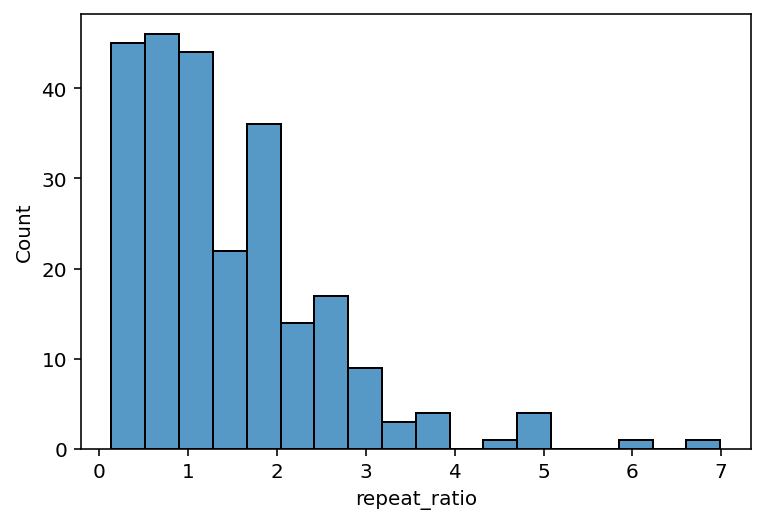

In [14]:


sns.histplot(prs_rrs_repeat_df.repeat_ratio)

<AxesSubplot:xlabel='repeat_ratio_log2', ylabel='Count'>

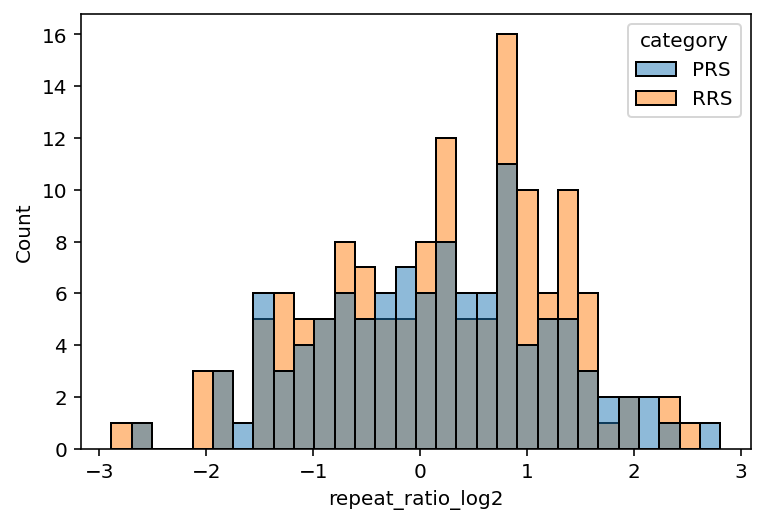

In [15]:
sns.histplot(data=prs_rrs_repeat_df, x=prs_rrs_repeat_df.repeat_ratio_log2, bins=30, hue='category')

In [16]:
np.mean(prs_rrs_repeat_df.repeat_ratio_log2), np.std(prs_rrs_repeat_df.repeat_ratio_log2), 

(0.14725061698202435, 1.082040612651034)

In [17]:
np.mean(prs_rrs_repeat_df.repeat_ratio_log2)

0.14725061698202435

In [18]:
np.mean(prs_rrs_repeat_df[prs_rrs_repeat_df.category == 'RRS'].repeat_ratio)

1.4387881230300135

In [19]:
np.mean(prs_rrs_repeat_df[prs_rrs_repeat_df.category == 'RRS'].repeat_ratio_log2)

0.1530939117125239

In [20]:
np.mean(prs_rrs_repeat_df[prs_rrs_repeat_df.category == 'PRS'].repeat_ratio_log2)

0.1398526842039607

In [21]:
np.std(prs_rrs_repeat_df[prs_rrs_repeat_df.category == 'RRS'].repeat_ratio_log2)

1.0942348133446427

In [22]:
np.std(prs_rrs_repeat_df.repeat_ratio_log2)

1.082040612651034

In [23]:
np.std(prs_rrs_repeat_df.repeat_ratio)

1.0675167508641326

In [24]:
(60*2+78*2)*2

552

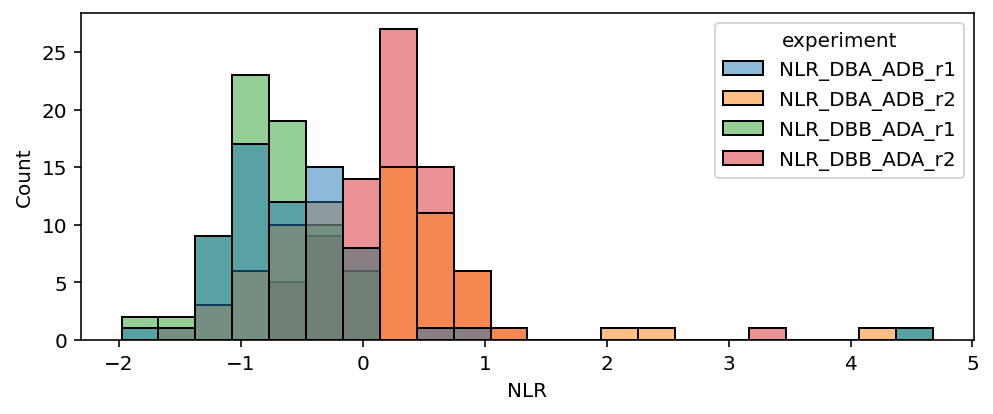

green 1.96 1.4497596440810316
lightblue 2 1.4833795834757928
salmon 2.326 1.7573820895430956
orange 3 2.3238780683448192


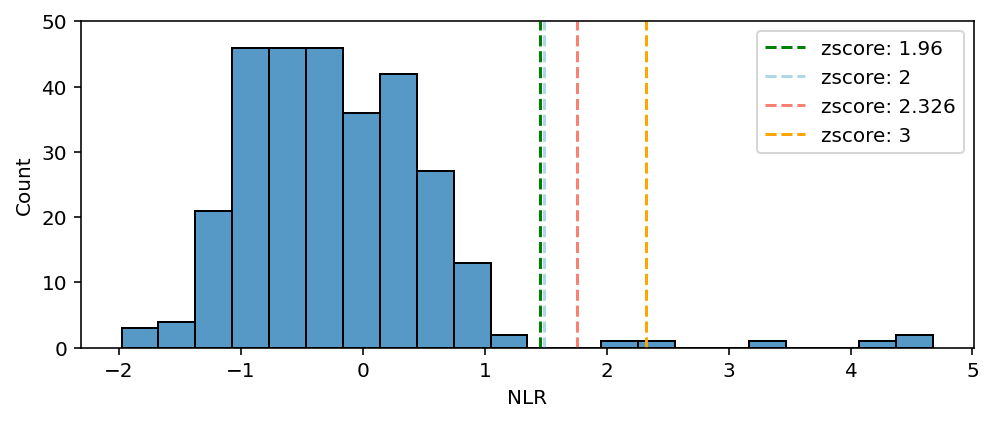

In [25]:
plt.figure(figsize=(8,3))
sns.histplot(data=rrs_df, x='NLR', hue='experiment')
plt.show()

plt.figure(figsize=(8,3))
sns.histplot(data=rrs_df, x='NLR')
for color,(zscore,threshold) in zip(['green','lightblue','salmon','orange'],rrs_all_thresholds_d.items()):
    print(color,zscore,threshold)
    plt.vlines(x=threshold, ymin=0, ymax=50, label=f'zscore: {zscore}', linestyles='--', color=color)
plt.ylim(0,50)
plt.legend()
plt.show()

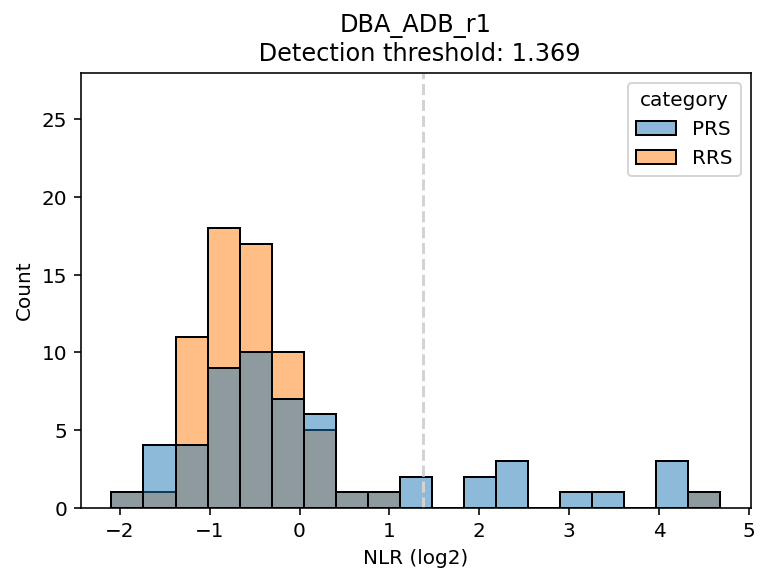

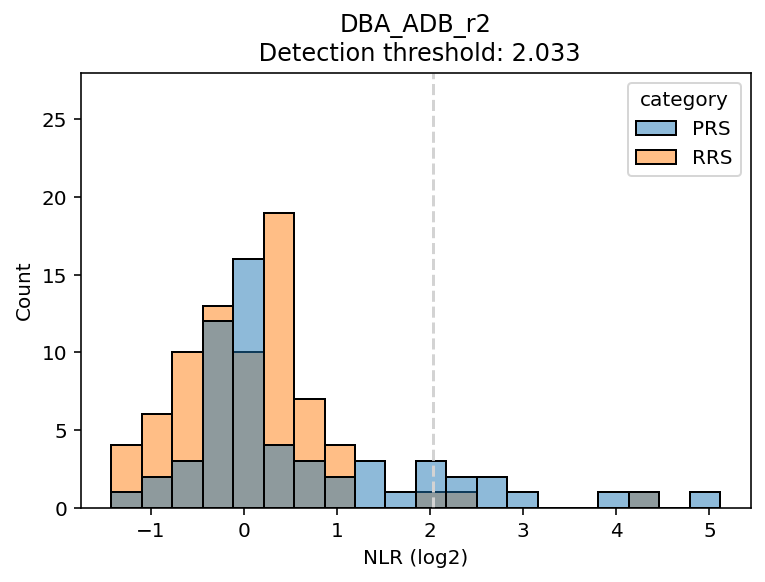

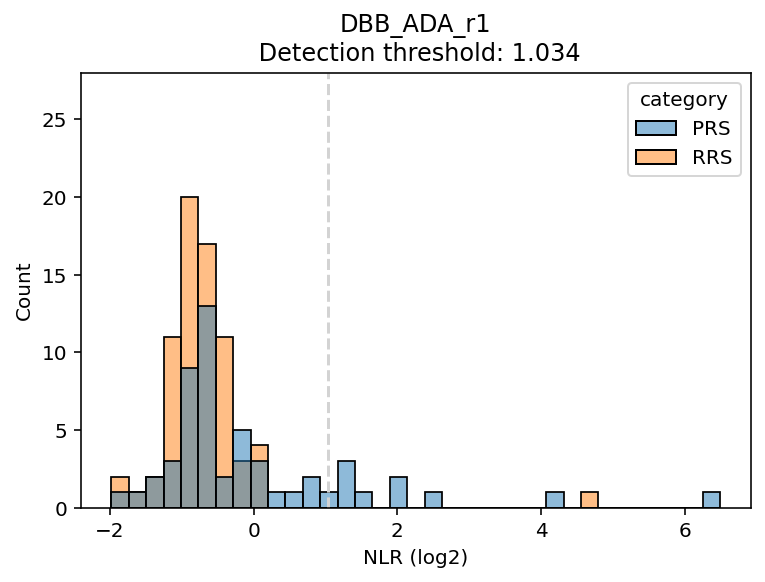

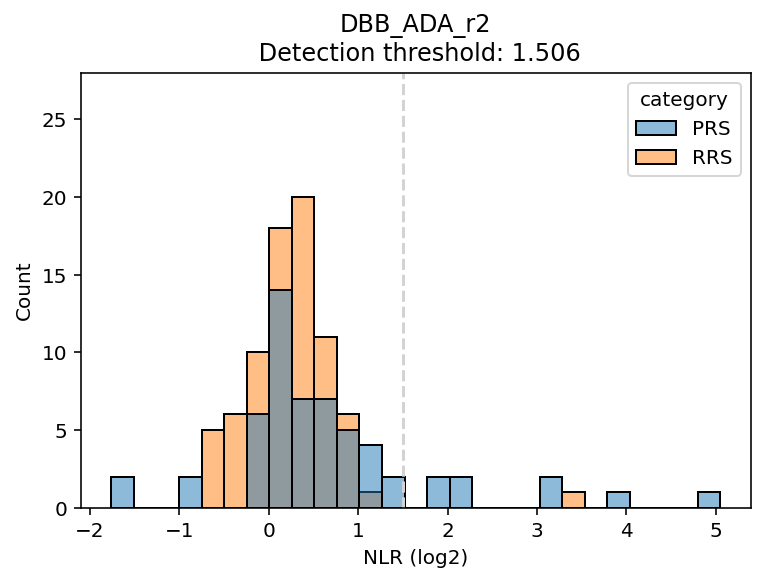

In [26]:
for orient in ['DBA_ADB','DBB_ADA']:
    for repeat in ['r1','r2']:
        plt.figure()
        threshold = thrshold_d[f'{orient}_{repeat}']
        plt.title(f"{orient}_{repeat}\n Detection threshold: {round(threshold,3)}")
        plt.vlines(ymin=0, ymax=28, x=thrshold_d[f'{orient}_{repeat}'], linestyles='--', color='lightgrey')
        plt.ylim(0,28)
        sns.histplot(data=prsrrsv2, x=f'NLR_{orient}_{repeat}', hue='category', legend=True)
        plt.xlabel('NLR (log2)')
        ;

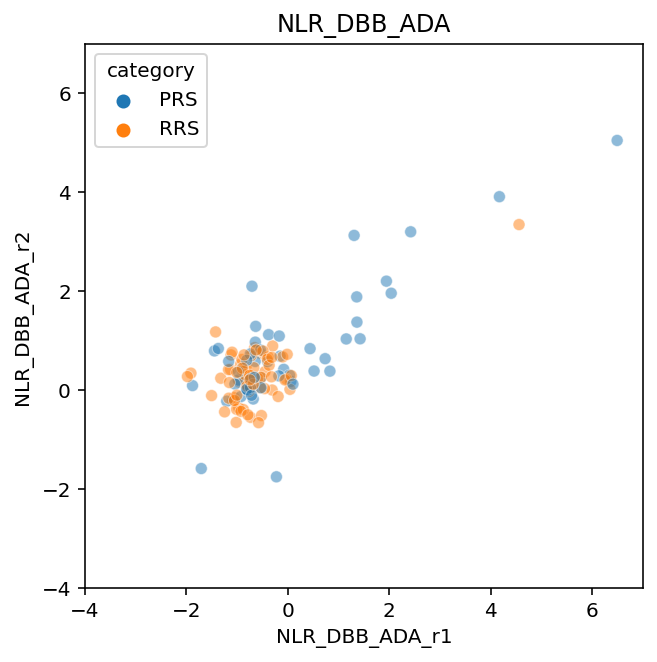

In [27]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=prsrrsv2, x='NLR_DBB_ADA_r1', y='NLR_DBB_ADA_r2', hue='category', alpha=.5)

plt.xlim(-4,7)
plt.ylim(-4,7)
plt.title('NLR_DBB_ADA')
plt.show()

DBA_ADB DBA_ADB r1 r2


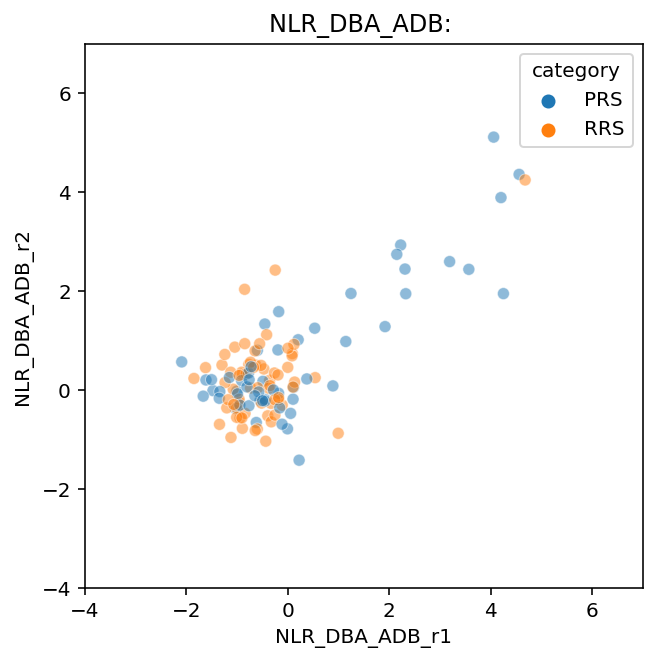

DBB_ADA DBB_ADA r1 r2


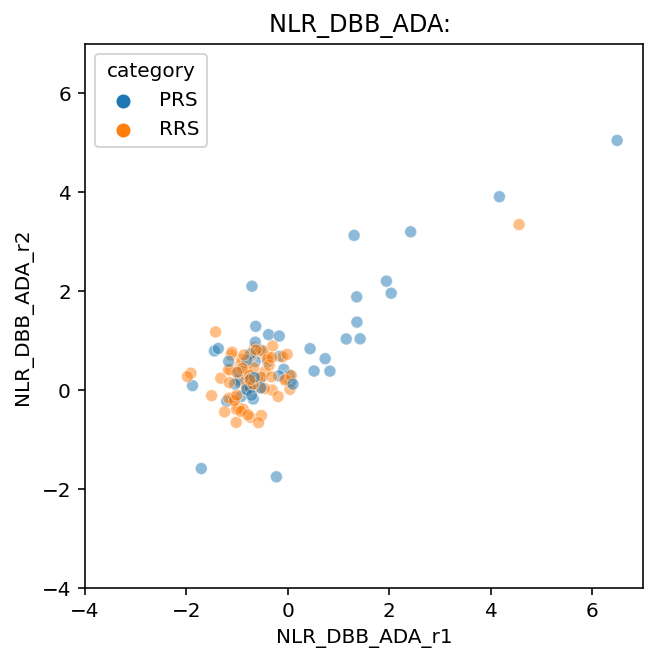

In [28]:
tested=set()
for orient1 in ['DBA_ADB','DBB_ADA']:
    for orient2 in ['DBA_ADB','DBB_ADA']:
        for repeat1 in ['r1','r2']:
            for repeat2 in ['r1','r2']:
                if orient1 == orient2 and repeat1 != repeat2 and (orient1,repeat1,repeat2) not in tested:
                    print(orient1,orient2,repeat1,repeat2)
                    tested.add((orient1,repeat2,repeat1))

                    plt.figure(figsize=(5,5))
                    sns.scatterplot(data=prsrrsv2, x=f'NLR_{orient1}_{repeat1}', y=f'NLR_{orient2}_{repeat2}', hue='category', alpha=.5)

                    plt.xlim(-4,7)
                    plt.ylim(-4,7)
                    plt.title(f'NLR_{orient1}: ')
                    plt.show()


In [29]:
retest_df = pd.read_csv('NY2H_APWT_summary_file.csv')
retest_df = retest_df[retest_df.dest_pla_id < 79].copy()
retest_df['RLU'] = [res[pla,well] for pla,well in zip(retest_df.dest_pla_id, retest_df.dest_well)]
retest_df['RLU_log10'] = retest_df.RLU.apply(np.log10)
retest_df['empty_well'] = [False if pla not in empty_well_retest_d else well in empty_well_retest_d[pla] for pla,well in zip(retest_df.dest_pla_id, retest_df.dest_well)]
retest_df['invalid'] = retest_df.empty_well | (retest_df.RLU_log10 < 2.85)

retest_df.head()

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,db_source_plate,db_source_well,ad_source_plate,ad_source_well,dest_well_id,dest_well,dest_pla_id,db_dest_pla,ad_dest_pla,RLU,RLU_log10,empty_well,invalid
0,1739.0,BMPR1A,0.0,100014367.0,BMP2,1.0,kd,NY2H_KdGDDh02,A07,NY2H_KdGDAh04,A01,1,A01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01,12671,4.102811,False,False
1,1739.0,BMPR1A,0.0,0.0,empty_ad1,1.0,kd,NY2H_KdGDDh02,A07,ctrl_pla,A01,2,B01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01,18984,4.278388,False,False
2,100014367.0,BMP2,0.0,1739.0,BMPR1A,1.0,kd,NY2H_KdGDDh04,A01,NY2H_KdGDAh02,A07,3,C01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01,23360,4.368473,False,False
3,100014367.0,BMP2,0.0,0.0,empty_ad1,1.0,kd,NY2H_KdGDDh04,A01,ctrl_pla,A01,4,D01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01,27489,4.439159,False,False
4,NaN,NaN,NaN,NaN,NaN,NaN,secret_code,NaN,NaN,NaN,NaN,5,E01,1,NY2H_APWT_DB_01,NY2H_APWT_AD_01,55,1.740363,True,True


In [30]:
ead_d = dict()
col = ['db_orf_id','db_mut_id','assay_id','RLU']
for i, (db_orf_id,db_mut_id,assay_id,RLU) in retest_df.query('ad_orf_id == 0 and empty_well == False and invalid == False')[col].iterrows():
    ead_d[(db_orf_id,db_mut_id,assay_id)] = RLU
    
col = ['db_orf_id', 'db_symbol', 'db_mut_id', 'ad_orf_id', 'ad_symbol','assay_id', 'retest_type', 'RLU', 'RLU_log10','empty_well','invalid']

normalized_df = retest_df.query("retest_type.isin(['nY2H_APWT','kd']) and ad_orf_id != 0")[col].copy()
normalized_df['RLU_ctrl'] = [ead_d[db_orf_id,db_mut_id,assay_id] if (db_orf_id,db_mut_id,assay_id) in ead_d else np.nan  for db_orf_id,db_mut_id,assay_id in zip(normalized_df.db_orf_id, normalized_df.db_mut_id, normalized_df.assay_id)]
normalized_df['NLR'] = [np.log2(rlu/ctrl) if not invalid and ctrl == ctrl else np.nan for rlu,ctrl,invalid in zip(normalized_df.RLU, normalized_df.RLU_ctrl, normalized_df.invalid)]

#detection threshold:  1.7573820895430956
normalized_df['detected'] = normalized_df.NLR >= 1.7573820895430956

#normalized_df['avg_NLR']

normalized_df.head()

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected
0,1739.0,BMPR1A,0.0,100014367.0,BMP2,1.0,kd,12671,4.102811,False,False,18984.0,-0.583254,False
2,100014367.0,BMP2,0.0,1739.0,BMPR1A,1.0,kd,23360,4.368473,False,False,27489.0,-0.234814,False
5,54387.0,FLT3LG,0.0,54530.0,FLT3,1.0,kd,11682,4.067517,False,False,16394.0,-0.488881,False
7,13530.0,LCN2,0.0,55203.0,FN1,1.0,kd,12760,4.105851,False,False,10219.0,0.320374,False
11,55203.0,FN1,0.0,13530.0,LCN2,1.0,kd,22948,4.360745,False,False,23648.0,-0.043350,False


In [31]:
pd.Series(zip(normalized_df[normalized_df.db_mut_id == 0].db_orf_id, normalized_df[normalized_df.db_mut_id == 0].ad_orf_id)).value_counts()

(1739.0, 100014367.0)         1
(54308.0, 100069191.0)        1
(52920.0, 11132.0)            1
(52920.0, 71838.0)            1
(12739.0, 100009390.0)        1
(56582.0, 71178.0)            1
(56582.0, 100000407.0)        1
(52920.0, 1235.0)             1
(52920.0, 71715.0)            1
(14973.0, 100011278.0)        1
(14973.0, 100066360.0)        1
(52920.0, 10064.0)            1
(52920.0, 71001.0)            1
(145.0, 145.0)                1
(52920.0, 6759.0)             1
(52920.0, 56215.0)            1
(52920.0, 1863.0)             1
(143.0, 14891.0)              1
(52920.0, 11567.0)            1
(52920.0, 2845.0)             1
(52920.0, 70054.0)            1
(3449.0, 4519.0)              1
(54175.0, 11648.0)            1
(54175.0, 56644.0)            1
(71337.0, 10441.0)            1
(71337.0, 70264.0)            1
(71337.0, 54668.0)            1
(52920.0, 14441.0)            1
(3727.0, 1586.0)              1
(52920.0, 439.0)              1
(5066.0, 4955.0)              1
(5066.0,

## Allele DF

In [32]:
normalized_df.head()

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected
0,1739.0,BMPR1A,0.0,100014367.0,BMP2,1.0,kd,12671,4.102811,False,False,18984.0,-0.583254,False
2,100014367.0,BMP2,0.0,1739.0,BMPR1A,1.0,kd,23360,4.368473,False,False,27489.0,-0.234814,False
5,54387.0,FLT3LG,0.0,54530.0,FLT3,1.0,kd,11682,4.067517,False,False,16394.0,-0.488881,False
7,13530.0,LCN2,0.0,55203.0,FN1,1.0,kd,12760,4.105851,False,False,10219.0,0.320374,False
11,55203.0,FN1,0.0,13530.0,LCN2,1.0,kd,22948,4.360745,False,False,23648.0,-0.043350,False


In [33]:
normalized_df.retest_type.value_counts()

nY2H_APWT    4569
kd            325
Name: retest_type, dtype: int64

In [35]:
allele_df = normalized_df.query("retest_type == 'nY2H_APWT' and db_mut_id > 0 and ~NLR.isnull()").copy()
#allele_df['nt_change'] = [mut_d[orf_id,mut_id][0] for orf_id, mut_id in zip(allele_df.N1_orf_id, allele_df.N1_mut_id)]
#allele_df['aa_change'] = [mut_d[orf_id,mut_id][1] for orf_id, mut_id in zip(allele_df.N1_orf_id, allele_df.N1_mut_id)]
#allele_df['clinical_significance'] = [mut_d[orf_id,mut_id][2] for orf_id, mut_id in zip(allele_df.N1_orf_id, allele_df.N1_mut_id)]

df = normalized_df.query("retest_type == 'nY2H_APWT' and db_mut_id == 0")
wt_NLR_d = dict(zip(df.db_orf_id, df.NLR))
allele_df['WT_NLR'] = allele_df.db_orf_id.map(wt_NLR_d)
#allele_df = allele_df[~allele_df.WT_NLR.isnull()].copy() #remove only one allele-WT
allele_df['AWT_ratio'] = allele_df.NLR / allele_df.WT_NLR

#df = normalized_df.query("retest_type == 'RRS' and avg_NLR < 800")
#l = [np.mean([nlr1,nlr2]) for nlr1,nlr2 in zip(df.NLR1, df.NLR2) if nlr1 == nlr1 and nlr2 == nlr2]
std_rrs, mean_rrs = np.mean(prs_rrs_repeat_df.repeat_ratio_log2), np.std(prs_rrs_repeat_df.repeat_ratio_log2)
allele_df['z_WT_NLR'] = allele_df.WT_NLR.apply(lambda x: (x-mean_rrs)/std_rrs)
allele_df['WT_detected'] = allele_df.z_WT_NLR.apply(lambda x: x >= 2.23)

std_ratio = np.std(prs_rrs_repeat_df.repeat_ratio_log2)
mean_ratio = np.mean(prs_rrs_repeat_df.repeat_ratio_log2)
allele_df['z_perturbation'] = allele_df.AWT_ratio.apply(lambda x: (np.log2(x)-mean_ratio)/std_ratio)
##allele_df['z_cat'] = allele_df.z_perturbation.apply(lambda x: 'increase_ppi' if x>=3 else 'decrease_ppi' if x<=-3 else 'no_perturbation')
allele_df['z_cat'] = ['not_detected' if not wt_detected else 'increase_ppi' if zp>=2 else 'decrease_ppi' if zp<=-2 else 'no_perturbation' for zp,wt_detected in zip(allele_df.z_perturbation, allele_df.WT_detected)] 

allele_df.head()

,db_orf_id,db_symbol,db_mut_id,ad_orf_id,ad_symbol,assay_id,retest_type,RLU,RLU_log10,empty_well,invalid,RLU_ctrl,NLR,detected,WT_NLR,AWT_ratio,z_WT_NLR,WT_detected,z_perturbation,z_cat
694,11805.0,SMAD3,2134.0,71704.0,SMURF2,1.0,nY2H_APWT,238037,5.376644,False,False,16380.0,3.861179,True,-0.123745,-31.202595,-8.188665,False,NaN,not_detected
695,11805.0,SMAD3,2145.0,71704.0,SMURF2,1.0,nY2H_APWT,198593,5.297964,False,False,26273.0,2.918162,True,-0.123745,-23.581977,-8.188665,False,NaN,not_detected
696,11805.0,SMAD3,2173.0,71704.0,SMURF2,1.0,nY2H_APWT,758081,5.879716,False,False,48924.0,3.953738,True,-0.123745,-31.950576,-8.188665,False,NaN,not_detected
697,11805.0,SMAD3,2117.0,71704.0,SMURF2,1.0,nY2H_APWT,407918,5.610573,False,False,48497.0,3.072312,True,-0.123745,-24.827678,-8.188665,False,NaN,not_detected
698,11805.0,SMAD3,203607.0,71704.0,SMURF2,1.0,nY2H_APWT,261063,5.416745,False,False,66868.0,1.965010,True,-0.123745,-15.879456,-8.188665,False,NaN,not_detected


In [36]:
allele_df[allele_df.WT_detected].z_cat.value_counts()

no_perturbation    1864
decrease_ppi        388
increase_ppi          1
Name: z_cat, dtype: int64

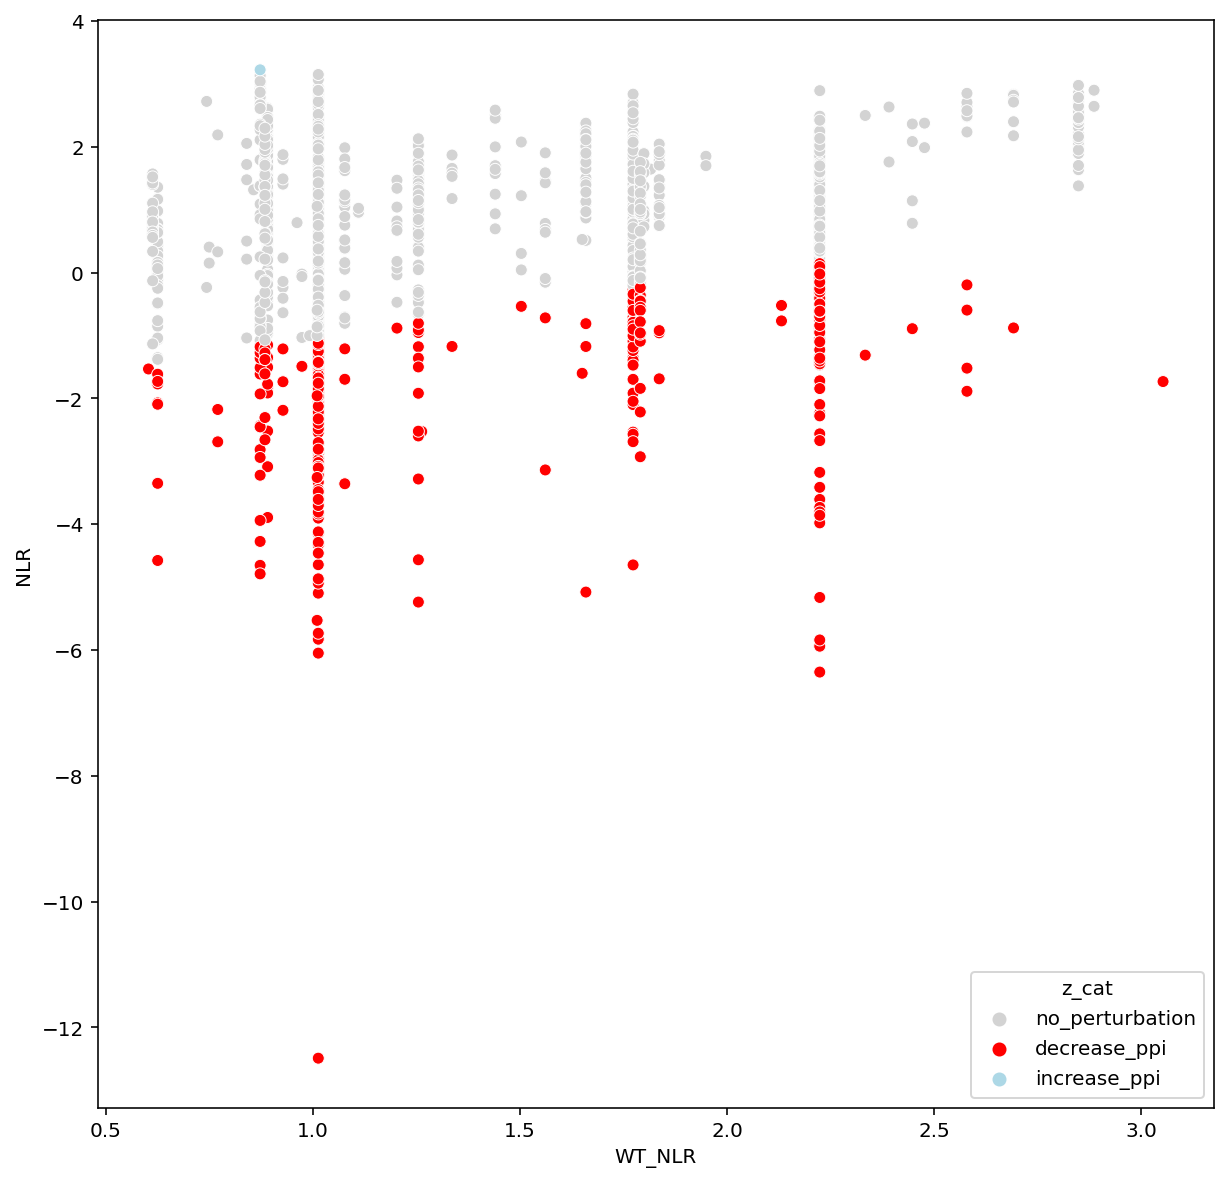

In [37]:
plt.figure(figsize=(10,10))
ax = sns.scatterplot(data=allele_df[allele_df.WT_detected], x=allele_df.WT_NLR.apply(np.log2), 
                     y=allele_df.NLR.apply(np.log2), hue='z_cat',palette={'not_detected':'gray',
                                                                              'increase_ppi':'lightblue',
                                                                              'decrease_ppi':'red',
                                                                              'no_perturbation':'lightgray'}
                    )


#plt.xlim(-2,10)
#plt.ylim(-7,10)
plt.show()

In [38]:
allele_df[(allele_df.WT_detected)&(allele_df.clin)].z_cat.value_counts().sort_index().plot.pie(colors=['red','lightblue','lightgray','gray']);
plt.ylabel('');

AttributeError: 'DataFrame' object has no attribute 'clin'

In [ ]:
nY2H = {(db_orf_id,db_mut_id,ad_orf_id):(WT_detected,NLR,WT_NLR,AWT_ratio,z_perturbation,z_cat) 
               for db_orf_id,db_mut_id,ad_orf_id,WT_detected,NLR,WT_NLR,AWT_ratio,z_perturbation,z_cat 
               in zip(allele_df.db_orf_id,allele_df.db_mut_id,allele_df.ad_orf_id,
                      allele_df.WT_detected,allele_df.NLR,allele_df.WT_NLR,allele_df.AWT_ratio,allele_df.z_perturbation,allele_df.z_cat)
              }


big_table = pd.read_csv('../../nanoluc_Y2H/VUSAPWT_hsPRSRRSv2_Choi_Kd/edgotyping_y2h_n2h_pdest_table.tsv',sep='\t')
big_table['nY2H_AWT_r'] = [nY2H[db_o,db_m,ad_o][3] if (db_o,db_m,ad_o) in nY2H else np.nan for db_o,db_m,ad_o in zip(big_table.db_orf_id,big_table.db_mut_id,big_table.ad_orf_id)]
big_table['nY2H_WT_pos'] = [nY2H[db_o,db_m,ad_o][0] if (db_o,db_m,ad_o) in nY2H else np.nan for db_o,db_m,ad_o in zip(big_table.db_orf_id,big_table.db_mut_id,big_table.ad_orf_id)]
big_table['nY2H_pert_cat'] = [nY2H[db_o,db_m,ad_o][-1] if (db_o,db_m,ad_o) in nY2H else np.nan for db_o,db_m,ad_o in zip(big_table.db_orf_id,big_table.db_mut_id,big_table.ad_orf_id)]

big_table.head()

In [ ]:
big_table[['ad_orf_id','db_orf_id','db_mut_id','nY2H_AWT_r','nY2H_WT_pos','nY2H_pert_cat']].to_csv('nY2H_res.csv', index=False)

In [ ]:
plt.figure(figsize=(15,4))
sns.stripplot(data=big_table[big_table.nY2H_WT_pos == True], x='q_perturb', y=big_table.nY2H_AWT_r.apply(np.log2), hue='nY2H_pert_cat', palette={'decrease_ppi':'red',
                                                                                                                                                 'increase_ppi':'lightblue',
                                                                                                                                                 'no_perturbation':'lightgray'}
             )
plt.xlabel('qY2H 3AT perturbation score')
plt.ylabel('nY2H Allele / WT (log2)')
plt.show()

In [ ]:
fig, (ax1,ax2,ax3,ax4,ax5,ax6) = plt.subplots(1, 6,figsize=(20, 20))
for ax,qpert in zip([ax1,ax2,ax3,ax4,ax5,ax6],[-3,-2,-1,0,1,2]):
    ax.set_title(f'n = {len(big_table[(big_table.nY2H_WT_pos == True)&(big_table.q_perturb == qpert)])}')
    if qpert == -3:
        colors = ['red','lightgray']
    elif qpert == 2:
        colors = ['lightgray']
    else:
        colors = ['red','lightgray']
        
    big_table[(big_table.nY2H_WT_pos == True)&(big_table.q_perturb == qpert)].nY2H_pert_cat.value_counts().sort_index().plot.pie(ax=ax, colors=colors,labeldistance=None)
    ax.set_ylabel('')
    
plt.show()